# Adaptive Traffic Signal Control with Tabular Q-Learning
### Notebook 1 of 2 — Environment & Training

**Objective.** Build a reinforcement-learning agent that controls a traffic light at a single
4-arm intersection, deciding in real time whether to *keep* the current green phase or *switch*
to the other one — instead of using a fixed, pre-set timer. The agent is trained and evaluated
inside [SUMO](https://sumo.dlr.de/) (Simulation of Urban MObility), an open-source traffic simulator,
controlled from Python via its **TraCI** (Traffic Control Interface) API.

**Why this project exists.** Fixed-time signals allocate the same green duration to every direction
regardless of how much traffic is actually waiting. On a road with uneven demand (a busy main road
crossing a quieter side road), that means the busy direction can back up while the quiet direction
gets a full green with nobody there — exactly the "wait through the same red light twice" experience
that motivated this project. An adaptive controller that reacts to the *actual* queue should do better.

**What this notebook does:**
1. Builds a small SUMO road network (one intersection, 4 approaches) from scratch
2. Defines traffic demand (asymmetric — one road busier than the other)
3. Wraps the simulation as an RL environment (state, action, reward)
4. Trains a tabular Q-learning agent to control the signal
5. Saves the trained Q-table for Notebook 2, which benchmarks it against fixed-time control

Notebook 2 (`02_evaluate_and_compare.ipynb`) does the "is this actually better?" comparison —
run this one first.

## Why tabular Q-learning (and not a neural network)?

This project intentionally uses **tabular** Q-learning rather than a Deep Q-Network (DQN), for reasons
worth stating explicitly if asked:

- The state space here is small and can be fully discretized (see below) — a lookup table fits in
  memory easily, so a function approximator (neural net) isn't *necessary* to make Q-learning tractable.
- Tabular Q-learning has convergence guarantees under standard conditions (every state-action pair
  visited infinitely often, appropriately decaying learning rate) — it's easier to reason about and
  to defend the correctness of, which matters for a project you'll be asked to explain.
- It keeps the RL logic and the traffic-domain logic decoupled from deep-learning debugging (weight
  initialization, network architecture, overfitting) — so problems in results are easier to attribute
  to the *traffic control strategy* rather than to *neural net training issues*.

The natural extension (mentioned again in the conclusion of Notebook 2) is to swap this tabular agent
for a DQN once the intersection has more approaches/lanes than a table can reasonably cover, or once
the state needs to include continuous / high-dimensional features SUMO doesn't natively discretize.

In [1]:
import os, sys, shutil, subprocess, time, random, pickle, json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

RANDOM_SEED = 0
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


## 1. Locating your SUMO installation

SUMO needs to be discoverable in two ways: the `sumo` / `netconvert` command-line binaries (used to
build the network and run the simulator), and the `SUMO_HOME/tools` directory (which contains the
`traci` Python package used to control the simulator step by step).

The cell below tries a few common install layouts automatically (Homebrew on Mac, a `pip install
eclipse-sumo` install, or an already-exported `SUMO_HOME`). If none of them match your setup, it will
tell you so explicitly — set `SUMO_HOME` yourself and re-run the cell rather than guessing.

In [2]:
def find_sumo_home():
    if "SUMO_HOME" in os.environ and os.path.isdir(os.environ["SUMO_HOME"]):
        return os.environ["SUMO_HOME"]
    sumo_bin = shutil.which("sumo")
    if sumo_bin:
        candidate = os.path.abspath(os.path.join(os.path.dirname(sumo_bin), "..", "share", "sumo"))
        if os.path.isdir(candidate):
            return candidate
    for candidate in ["/opt/homebrew/opt/sumo/share/sumo", "/usr/local/opt/sumo/share/sumo"]:
        if os.path.isdir(candidate):
            return candidate
    try:
        import sumo as sumo_pkg
        candidate = os.path.dirname(sumo_pkg.__file__)
        if os.path.isdir(candidate):
            return candidate
    except ImportError:
        pass
    return None

SUMO_HOME = find_sumo_home()
if SUMO_HOME is None:
    raise RuntimeError(
        "Could not auto-detect SUMO_HOME.\n"
        "If you installed SUMO via Homebrew, run `brew --prefix sumo` in a terminal, then set:\n"
        "    import os; os.environ['SUMO_HOME'] = '<that path>/share/sumo'\n"
        "and re-run this cell."
    )
os.environ["SUMO_HOME"] = SUMO_HOME
os.environ["PATH"] = os.path.join(SUMO_HOME, "bin") + os.pathsep + os.environ.get("PATH", "")
sys.path.append(os.path.join(SUMO_HOME, "tools"))

import traci

print("SUMO_HOME:      ", SUMO_HOME)
print("sumo binary:    ", shutil.which("sumo"))
print("netconvert:     ", shutil.which("netconvert"))


SUMO_HOME:       /Users/sarvesh/Projects/Trafiic-Project/.venv/lib/python3.12/site-packages/sumo
sumo binary:     /Users/sarvesh/Projects/Trafiic-Project/.venv/lib/python3.12/site-packages/sumo/bin/sumo
netconvert:      /Users/sarvesh/Projects/Trafiic-Project/.venv/lib/python3.12/site-packages/sumo/bin/netconvert


## 2. Building the road network

We model **one intersection with four arms** (north / south / east / west), each a single lane in
each direction, and — to keep the state and action spaces small enough for a lookup table — **through
traffic only** (no turning movements). This is a simplification worth stating up front if asked about
it: real intersections have turns; this project isolates the *signal-timing* decision from the
*routing/turning* decision so the RL part stays clean and explainable. Multi-lane, turn-aware control
is left as future work.

SUMO networks are normally built with `netconvert` from three plain-text descriptions:
- **nodes** (`.nod.xml`) — the intersection and the four arm endpoints, with (x, y) coordinates
- **edges** (`.edg.xml`) — the road segments connecting those nodes (SUMO edges are directional, so
  each arm needs one edge *into* the intersection and one *out of* it)
- **connections** (`.con.xml`) — which incoming edge is allowed to feed which outgoing edge (this is
  where we restrict to through-traffic only)

In [3]:
NET_DIR = "network"
os.makedirs(NET_DIR, exist_ok=True)

with open(f"{NET_DIR}/nodes.nod.xml", "w") as f:
    f.write('''<nodes>
    <node id="center" x="0" y="0" type="traffic_light"/>
    <node id="north"  x="0" y="200" type="priority"/>
    <node id="south"  x="0" y="-200" type="priority"/>
    <node id="east"   x="200" y="0" type="priority"/>
    <node id="west"   x="-200" y="0" type="priority"/>
</nodes>''')

with open(f"{NET_DIR}/edges.edg.xml", "w") as f:
    f.write('''<edges>
    <edge id="N2C" from="north" to="center" numLanes="1" speed="13.89"/>
    <edge id="C2N" from="center" to="north" numLanes="1" speed="13.89"/>
    <edge id="S2C" from="south" to="center" numLanes="1" speed="13.89"/>
    <edge id="C2S" from="center" to="south" numLanes="1" speed="13.89"/>
    <edge id="E2C" from="east" to="center" numLanes="1" speed="13.89"/>
    <edge id="C2E" from="center" to="east" numLanes="1" speed="13.89"/>
    <edge id="W2C" from="west" to="center" numLanes="1" speed="13.89"/>
    <edge id="C2W" from="center" to="west" numLanes="1" speed="13.89"/>
</edges>''')

with open(f"{NET_DIR}/connections.con.xml", "w") as f:
    f.write('''<connections>
    <connection from="N2C" to="C2S" fromLane="0" toLane="0"/>
    <connection from="S2C" to="C2N" fromLane="0" toLane="0"/>
    <connection from="E2C" to="C2W" fromLane="0" toLane="0"/>
    <connection from="W2C" to="C2E" fromLane="0" toLane="0"/>
</connections>''')

result = subprocess.run(
    ["netconvert",
     "--node-files", f"{NET_DIR}/nodes.nod.xml",
     "--edge-files", f"{NET_DIR}/edges.edg.xml",
     "--connection-files", f"{NET_DIR}/connections.con.xml",
     "-o", f"{NET_DIR}/intersection.net.xml"],
    capture_output=True, text=True
)
print(result.stdout, result.stderr)
assert result.returncode == 0, "netconvert failed -- see output above"
print("Network built ->", f"{NET_DIR}/intersection.net.xml")


Success.
 
Network built -> network/intersection.net.xml


**Checking the generated traffic-light logic.** `netconvert` automatically detects the conflicting
movements at the junction and writes a default traffic-light program. With through-traffic-only
connections, this collapses to exactly the classic 2-phase signal we want: North+South green together,
then East+West green together, each followed by a short yellow.

In [4]:
with open(f"{NET_DIR}/intersection.net.xml") as f:
    net_xml = f.read()
start = net_xml.index('<tlLogic')
end = net_xml.index('</tlLogic>') + len('</tlLogic>')
print(net_xml[start:end])
print()
print("incLanes order (link index -> approach): N2C(0), E2C(1), S2C(2), W2C(3)")
print("Phase 0 'GrGr' = N and S green (link 0 & 2), E and W red")
print("Phase 2 'rGrG' = E and W green (link 1 & 3), N and S red")
print("Phases 1 and 3 are the yellow transitions between them")


<tlLogic id="center" type="static" programID="0" offset="0">
        <phase duration="42" state="GrGr"/>
        <phase duration="3"  state="yryr"/>
        <phase duration="42" state="rGrG"/>
        <phase duration="3"  state="ryry"/>
    </tlLogic>

incLanes order (link index -> approach): N2C(0), E2C(1), S2C(2), W2C(3)
Phase 0 'GrGr' = N and S green (link 0 & 2), E and W red
Phase 2 'rGrG' = E and W green (link 1 & 3), N and S red
Phases 1 and 3 are the yellow transitions between them


## 3. Traffic demand

Demand is defined in a `.rou.xml` (routes) file as **flows**: a vehicle type plus a rate
(vehicles/hour) over a time window. We deliberately make North–South **twice as busy** as
East–West (400 vs 200 veh/h) — an asymmetric load is what actually exposes the weakness of
fixed-time control (a fixed 50/50 split wastes green time on the quiet direction while the busy
one queues up), and it mirrors the real, uneven traffic that motivated this project.

The simulation runs for a simulated **hour** (3600s) per episode.

In [5]:
with open(f"{NET_DIR}/routes.rou.xml", "w") as f:
    f.write('''<routes>
    <vType id="car" accel="2.6" decel="4.5" sigma="0.5" length="5" minGap="2.5" maxSpeed="16.67"/>

    <route id="r_N2S" edges="N2C C2S"/>
    <route id="r_S2N" edges="S2C C2N"/>
    <route id="r_E2W" edges="E2C C2W"/>
    <route id="r_W2E" edges="W2C C2E"/>

    <flow id="f_N2S" type="car" route="r_N2S" begin="0" end="3600" vehsPerHour="400" departSpeed="max"/>
    <flow id="f_S2N" type="car" route="r_S2N" begin="0" end="3600" vehsPerHour="400" departSpeed="max"/>
    <flow id="f_E2W" type="car" route="r_E2W" begin="0" end="3600" vehsPerHour="200" departSpeed="max"/>
    <flow id="f_W2E" type="car" route="r_W2E" begin="0" end="3600" vehsPerHour="200" departSpeed="max"/>
</routes>''')

with open(f"{NET_DIR}/simulation.sumocfg", "w") as f:
    f.write('''<configuration>
    <input>
        <net-file value="intersection.net.xml"/>
        <route-files value="routes.rou.xml"/>
    </input>
    <time>
        <begin value="0"/>
        <end value="3600"/>
    </time>
</configuration>''')

SUMOCFG = f"{NET_DIR}/simulation.sumocfg"
print("Demand + config written. Total demand: 400+400+200+200 = 1200 veh/h across the intersection.")


Demand + config written. Total demand: 400+400+200+200 = 1200 veh/h across the intersection.


## 4. RL formulation

**State.** The number of vehicles currently *halted* (stopped, queued) on each of the 4 incoming
approaches, plus which pair is currently green. Raw halting counts are continuous-ish and unbounded,
so for a *tabular* method we discretize each count into 4 buckets — this is the standard reason
tabular methods bucket continuous signals: it keeps the table size fixed and finite:

| Halting vehicles | Bucket |
|---|---|
| 0 | 0 |
| 1–2 | 1 |
| 3–5 | 2 |
| 6+ | 3 |

State = `(bucket_N, bucket_E, bucket_S, bucket_W, current_green)` — at most 4⁴ × 2 = 512 distinct
states, small enough for an exact table (no function approximation needed).

**Action.** Binary: `0 = keep the current green phase`, `1 = switch to the other phase` (which
triggers a fixed yellow transition first — the agent doesn't control the yellow itself; that's a
fixed safety interval, not a strategic decision).

A **minimum green time** of 10s is enforced — the agent's request to switch is ignored if the
current phase hasn't been green for at least that long. This models a real safety/practicality
constraint (you can't legally or sensibly flip a light back and forth every second) and also keeps
the state space from being dominated by pathological rapid-switching behavior early in training.

**Reward.** At each decision point, the environment advances the simulation by a fixed **decision
interval** (5s of simulated time, plus 3s of yellow if a switch just happened) and sums the number of
halted vehicles at every simulated second in between. The reward is the **negative** of that sum — the
agent is directly rewarded for minimizing accumulated queuing, which is the quantity we actually care
about reducing.

In [6]:
TLS_ID = "center"
INCOMING_EDGES = ["N2C", "E2C", "S2C", "W2C"]  # order matches the link index order netconvert assigned
GREEN_PHASES = [0, 2]                          # phase 0 = N/S green, phase 2 = E/W green
DECISION_INTERVAL = 5   # seconds of sim time between agent decisions
MIN_GREEN = 10          # seconds a phase must stay green before a switch is honoured
YELLOW_TIME = 3         # seconds of yellow when switching


def discretize(n):
    if n == 0: return 0
    if n <= 2: return 1
    if n <= 5: return 2
    return 3


class TrafficEnv:
    """Wraps one SUMO/TraCI simulation of the intersection as an RL environment."""

    def __init__(self, sumocfg, seed=None):
        self.sumocfg = sumocfg
        self.seed = seed
        self._started = False

    def _sim_args(self):
        args = ["-c", self.sumocfg, "--no-warnings", "--no-step-log"]
        args += ["--seed", str(self.seed)] if self.seed is not None else ["--random"]
        return args

    def reset(self):
        # Reload the scenario on a live SUMO process (traci.load) instead of killing and
        # restarting the process every episode. Restarting costs ~1s per episode (socket
        # handshake); reloading costs a couple of milliseconds -- this matters a lot once
        # you are training for hundreds of episodes.
        if not self._started:
            traci.start(["sumo"] + self._sim_args())
            self._started = True
        else:
            traci.load(self._sim_args())
        self.green_idx = 0
        traci.trafficlight.setPhase(TLS_ID, GREEN_PHASES[self.green_idx])
        self.time_in_phase = 0
        return self._get_state()

    def _get_state(self):
        halts = tuple(discretize(traci.edge.getLastStepHaltingNumber(e)) for e in INCOMING_EDGES)
        return halts + (self.green_idx,)

    def _accumulate_wait(self, n_steps):
        total = 0
        for _ in range(n_steps):
            traci.simulationStep()
            total += sum(traci.edge.getLastStepHaltingNumber(e) for e in INCOMING_EDGES)
        return total

    def step(self, action):
        cost = 0
        if action == 1 and self.time_in_phase >= MIN_GREEN:
            traci.trafficlight.setPhase(TLS_ID, GREEN_PHASES[self.green_idx] + 1)  # yellow
            cost += self._accumulate_wait(YELLOW_TIME)
            self.green_idx = 1 - self.green_idx
            traci.trafficlight.setPhase(TLS_ID, GREEN_PHASES[self.green_idx])
            self.time_in_phase = 0
        cost += self._accumulate_wait(DECISION_INTERVAL)
        self.time_in_phase += DECISION_INTERVAL
        done = traci.simulation.getTime() >= 3600
        return self._get_state(), -cost, done

    def close(self):
        if self._started:
            traci.close()
            self._started = False


print("TrafficEnv defined.")


TrafficEnv defined.


## 5. Q-learning agent

Standard tabular Q-learning with an epsilon-greedy exploration policy:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

| Hyperparameter | Value | Reasoning |
|---|---|---|
| Learning rate (α) | 0.1 | Standard moderate value; stable without being too slow |
| Discount factor (γ) | 0.9 | Cares about near-future congestion more than distant future within the hour-long episode |
| ε start → end | 1.0 → 0.05 | Fully random exploration at first (table is empty), decaying linearly over the first 200 episodes so the agent spends the remaining episodes mostly exploiting what it's learned |
| Episodes | 300 | Empirically enough for the ~36 states this scenario actually visits to converge (see learning curve below) |

The Q-table is a `dict` (via `defaultdict`) rather than a fixed-size array — most of the 512
theoretically possible states never occur in this traffic pattern, so this is more memory-efficient
than pre-allocating the full table, and is the standard idiom for tabular RL when the reachable state
space is a small subset of the theoretical one.

In [7]:
N_ACTIONS = 2
ALPHA = 0.1
GAMMA = 0.9
EPS_START = 1.0
EPS_END = 0.05
EPS_DECAY_EPISODES = 200
N_EPISODES = 300


class QLearningAgent:
    def __init__(self):
        self.Q = defaultdict(lambda: np.zeros(N_ACTIONS))

    def epsilon(self, ep):
        frac = min(ep / EPS_DECAY_EPISODES, 1.0)
        return EPS_START + frac * (EPS_END - EPS_START)

    def act(self, state, ep, greedy=False):
        if (not greedy) and random.random() < self.epsilon(ep):
            return random.randrange(N_ACTIONS)
        return int(np.argmax(self.Q[state]))

    def update(self, s, a, r, s_next, done):
        target = r if done else r + GAMMA * np.max(self.Q[s_next])
        self.Q[s][a] += ALPHA * (target - self.Q[s][a])


print("QLearningAgent defined.")


QLearningAgent defined.


## 6. Training loop

Each episode is one simulated hour of traffic. `avg_wait_per_step` (total accumulated halting,
divided by number of decision steps) is the metric to watch — lower means less average queuing,
and it's directly comparable across episodes since the episode length is fixed.

In [8]:
env = TrafficEnv(SUMOCFG, seed=None)
agent = QLearningAgent()
history = []

t0 = time.time()
for ep in range(N_EPISODES):
    s = env.reset()
    total_reward = 0
    done = False
    n_steps = 0
    while not done:
        a = agent.act(s, ep)
        s_next, r, done = env.step(a)
        agent.update(s, a, r, s_next, done)
        s = s_next
        total_reward += r
        n_steps += 1
    avg_wait = -total_reward / n_steps
    history.append({"episode": ep, "total_reward": total_reward,
                     "avg_wait_per_step": avg_wait, "epsilon": agent.epsilon(ep),
                     "n_states_seen": len(agent.Q)})
    if ep % 25 == 0 or ep == N_EPISODES - 1:
        print(f"ep {ep:4d} | reward {total_reward:8.1f} | avg_wait/step {avg_wait:6.2f} | "
              f"eps {agent.epsilon(ep):.3f} | states_seen {len(agent.Q)}")

env.close()
print(f"\nTraining took {time.time()-t0:.1f}s for {N_EPISODES} episodes")

with open("qtable.pkl", "wb") as f:
    pickle.dump(dict(agent.Q), f)
with open("train_history.json", "w") as f:
    json.dump(history, f)
print("Saved qtable.pkl and train_history.json for Notebook 2")


 Retrying in 1 seconds


Could not connect to TraCI server at localhost:49573 [Errno 61] Connection refused
 Retrying in 1 seconds


ep    0 | reward  -6515.0 | avg_wait/step  10.89 | eps 1.000 | states_seen 14


ep   25 | reward  -5761.0 | avg_wait/step   9.72 | eps 0.881 | states_seen 31


ep   50 | reward  -5220.0 | avg_wait/step   8.86 | eps 0.762 | states_seen 35


ep   75 | reward  -5084.0 | avg_wait/step   8.71 | eps 0.644 | states_seen 36


... (5 outputs left out)

ep  225 | reward  -3720.0 | avg_wait/step   6.44 | eps 0.050 | states_seen 39


ep  250 | reward  -4235.0 | avg_wait/step   7.34 | eps 0.050 | states_seen 39


ep  275 | reward  -3951.0 | avg_wait/step   6.82 | eps 0.050 | states_seen 39


ep  299 | reward  -3813.0 | avg_wait/step   6.61 | eps 0.050 | states_seen 39

Training took 138.1s for 300 episodes
Saved qtable.pkl and train_history.json for Notebook 2


## 7. Learning curve

If training worked, `avg_wait_per_step` should trend downward as epsilon decays and the agent shifts
from random exploration to exploiting what it's learned, then roughly flatten out once epsilon hits
its floor (0.05) and the policy has essentially converged for the states that occur often.

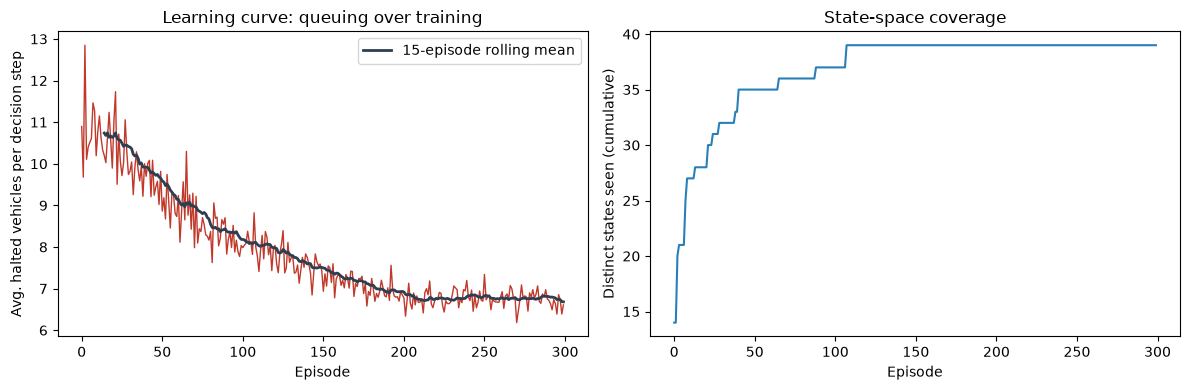

Avg wait/step -- first 25 episodes: 10.66, last 25 episodes: 6.73


In [9]:
episodes = [h["episode"] for h in history]
avg_waits = [h["avg_wait_per_step"] for h in history]
n_states = [h["n_states_seen"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(episodes, avg_waits, color="#c0392b", linewidth=1)
# rolling mean to see the trend through the exploration noise
window = 15
rolling = np.convolve(avg_waits, np.ones(window)/window, mode="valid")
axes[0].plot(episodes[window-1:], rolling, color="#2c3e50", linewidth=2, label=f"{window}-episode rolling mean")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Avg. halted vehicles per decision step")
axes[0].set_title("Learning curve: queuing over training")
axes[0].legend()

axes[1].plot(episodes, n_states, color="#2980b9")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Distinct states seen (cumulative)")
axes[1].set_title("State-space coverage")

plt.tight_layout()
plt.savefig("learning_curve.png", dpi=110)
plt.show()

print(f"Avg wait/step -- first 25 episodes: {np.mean(avg_waits[:25]):.2f}, "
      f"last 25 episodes: {np.mean(avg_waits[-25:]):.2f}")


**Reading this chart for an interview:** the first ~200 episodes are noisy because epsilon is
still high (the agent is mostly acting randomly to explore); the visible downward trend in the rolling
mean is the signal that the *greedy* part of the policy is improving even while exploration noise is
still present. Once epsilon hits its floor (episode 200 onward), the curve should flatten near its best
achievable value for this traffic pattern — that plateau is what "converged" looks like for tabular
Q-learning here.

Move to **`02_evaluate_and_compare.ipynb`** next — this notebook only shows the RL agent training
against itself; it doesn't yet tell you whether that's actually *better* than what a normal fixed-time
signal would do. That comparison, plus the numbers you'd want in hand for a viva, is entirely in
Notebook 2.